In [1]:
import pandas as pd
import warnings
import sys
from pathlib import Path
from datasets import load_dataset
import re
from collections import Counter
import numpy as np

In [2]:
warnings.simplefilter(action='ignore', category=FutureWarning) 

In [3]:
# Assuming the working directory is root/part1 or root/part2
root = Path.cwd().parent
sys.path.insert(0, str(root))
import part1

In [4]:
# save models and outputs there to keep the directory tree organised
results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True) 
results_folder

PosixPath('results')

In [5]:
# Login using e.g. `huggingface-cli login` to access this dataset
df = load_dataset("mteb/imdb")


value = df['train'][0]
print(value)

review = value['text']
print(review)

binary = value['label']
print(binary)

target = value['label_text']
print(target)


{'text': 'I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far be

In [6]:
imdb_outcome_space = part1.clslib.NamedClasses(['negative', 'positive'])
print(imdb_outcome_space)

0: negative, 1: positive


In [7]:
df_train = pd.DataFrame(df['train'])
display(df_train)

df_test = pd.DataFrame(df['test'])
display(df_test)

,text,label,label_text
0,I rented I AM CURIOUS-YELLOW from my video sto...,0,negative
1,"""I Am Curious: Yellow"" is a risible and preten...",0,negative
2,If only to avoid making this type of film in t...,0,negative
3,This film was probably inspired by Godard's Ma...,0,negative
4,"Oh, brother...after hearing about this ridicul...",0,negative
...,...,...,...
24899,A hit at the time but now better categorised a...,1,positive
24900,I love this movie like no other. Another time ...,1,positive
24901,This film and it's sequel Barry Mckenzie holds...,1,positive
24902,'The Adventures Of Barry McKenzie' started lif...,1,positive


,text,label,label_text
0,I love sci-fi and am willing to put up with a ...,0,negative
1,"Worth the entertainment value of a rental, esp...",0,negative
2,its a totally average film with a few semi-alr...,0,negative
3,STAR RATING: ***** Saturday Night **** Friday ...,0,negative
4,"First off let me say, If you haven't enjoyed a...",0,negative
...,...,...,...
24673,Just got around to seeing Monster Man yesterda...,1,positive
24674,I got this as part of a competition prize. I w...,1,positive
24675,I got Monster Man in a box set of three films ...,1,positive
24676,"Five minutes in, i started to feel how naff th...",1,positive


In [8]:
def clean(text):
    no_html = re.sub(r"</?(br|i|em|hr)\s*/?>", " ", text)
    no_space = " ".join(no_html.split())
    return no_space

In [9]:
dftrain_html = []

for i in df['train']['text']:
    dftrain_html.append(clean(i))

In [10]:
dftest_html = []

for i in df['test']['text']:
    dftest_html.append(clean(i))

In [11]:
print(sum("<br" in t for t in dftrain_html))   # should be 0
print(sum(">" in t for t in dftrain_html))     # should be small, not ~14,600
print(dftrain_html[0][:500])                   # read it: no tags, no stray >

0
42
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself. The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to mak


In [12]:
train_labels = list(df['train']['label'])
test_labels  = list(df['test']['label'])

print(sum("\t" in t for t in dftrain_html))
print(sum("\n" in t for t in dftrain_html))

0
0


We searched for anything that looks like a tag and inspected everything we found. Only real HTML (<br />, <i>, <em>, <hr>) was removed, replaced by a space so words don’t stick together. Things like <sigh> were kept because the reviewer wrote them. We also turned tabs and repeated spaces into single spaces, because the tokenizer only splits on normal spaces.

In [13]:
train_total = len(train_labels)
train_neg = Counter(train_labels)[0] / train_total * 100
train_pos = Counter(train_labels)[1] / train_total * 100

print(Counter(train_labels))  
print(train_neg)
print(train_pos)

Counter({1: 12472, 0: 12432})
49.91969161580469
50.080308384195305


In [14]:
test_total = len(test_labels)
test_neg = Counter(test_labels)[0] / test_total * 100
test_pos = Counter(test_labels)[1] / test_total * 100

print(Counter(test_labels))
print(test_neg)
print(test_pos)

Counter({1: 12412, 0: 12266})
49.70418996677202
50.29581003322797


In [15]:
df_train["text"] = df_train["text"].apply(clean)
df_test["text"]  = df_test["text"].apply(clean)

In [16]:
print(df_train["text"].duplicated().sum())               
print(df_test["text"].isin(df_train["text"]).sum())      
df_train = df_train.drop_duplicates(subset="text").reset_index(drop=True)
print(len(df_train))                                     

2
0
24902


In [17]:
dftrain_html = df_train["text"].tolist()
train_labels = df_train["label"].tolist()
dftest_html  = df_test["text"].tolist()
test_labels  = df_test["label"].tolist()

In [18]:
vocab_size = 1000
min_frequency = 2
tokenizer = part1.experiment.train_tokenizer(dftrain_html, vocab_size, min_frequency)

In [19]:
tokenizer.save(f"{results_folder}/BPE_tokenizer_vs_{vocab_size}_mf_{min_frequency}.json")

In [20]:
print(tokenizer.get_vocab_size())    # 1000
print(tokenizer.encode("This movie was not good, the acting was terrible.").tokens)

1000
['▁This', '▁movie', '▁was', '▁not', '▁good', ',', '▁the', '▁acting', '▁was', '▁ter', 'ri', 'ble', '.']


In [21]:
%%time
my_seeds = [0] # [0, 3, 5] # add more seeds here for multiple runs of cross validation, eg. [0, 3, 5]  
num_folds = 5  # more makes each cross validation run more statistically informative, but it can get slow
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        part1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(dftrain_html, train_labels)), 
            k=num_folds,
            seed=seed
        )
    )

CPU times: user 6.65 ms, sys: 200 μs, total: 6.85 ms
Wall time: 6.87 ms


Here's we'll implement the BoW encoder that's missing from the clslib.py file but required as per the checklist:
"_the two representation spaces in the tutorial (token indicators and bag-of-words) and an additional one of your choice._"

In [22]:
class BagOfWords(part1.clslib.Encoder):
    def __init__(self, tokenizer):
        self.tokenizer = tokenizer

    def __len__(self):
        return self.tokenizer.get_vocab_size()

    def __call__(self, x: str):
        token_ids = self.tokenizer.encode(x).ids
        vector = np.zeros(len(self))
        for tid in token_ids:
            vector[tid] += 1
        return vector


Main difference between BoW and TokenIndicator: TokenIndicator puts a 1 if a token appears (binary). BagOfWords counts how many times each token appears (integer counts). The for loop increments instead of assigning.

In [23]:
token_indicator_enc = part1.clslib.TokenIndicator(tokenizer)
bag_of_words_enc = BagOfWords(tokenizer)

In [25]:
my_classifiers = {}

# Log-linear + TokenIndicator
my_classifiers['logistic_indicator-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_indicator-enc/seed-{seed}"
    my_classifiers['logistic_indicator-enc'].append(
        part1.experiment.cross_validation_experiment(
            my_cross_validation_sets[run], imdb_outcome_space,
            token_indicator_enc, model_option='logistic', save_to=run_folder,
            loglin_args={'max_iter': 1000}
        )
    )

# Log-linear + BagOfWords
my_classifiers['logistic_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_bow-enc/seed-{seed}"
    my_classifiers['logistic_bow-enc'].append(
        part1.experiment.cross_validation_experiment(
            my_cross_validation_sets[run], imdb_outcome_space,
            bag_of_words_enc, model_option='logistic', save_to=run_folder,
            loglin_args={'max_iter': 1000}
        )
    )

# Commented so it doesn't run on laptop and take many hours
# # MLP + TokenIndicator
# my_classifiers['mlp_indicator-enc'] = []
# for run, seed in enumerate(my_seeds):
#     run_folder = f"{results_folder}/mlp_indicator-enc/seed-{seed}"
#     my_classifiers['mlp_indicator-enc'].append(
#         part1.experiment.cross_validation_experiment(
#             my_cross_validation_sets[run], imdb_outcome_space,
#             token_indicator_enc, model_option='mlp', save_to=run_folder
#         )
#     )
#
# # MLP + BagOfWords
# my_classifiers['mlp_bow-enc'] = []
# for run, seed in enumerate(my_seeds):
#     run_folder = f"{results_folder}/mlp_bow-enc/seed-{seed}"
#     my_classifiers['mlp_bow-enc'].append(
#         part1.experiment.cross_validation_experiment(
#             my_cross_validation_sets[run], imdb_outcome_space,
#             bag_of_words_enc, model_option='mlp', save_to=run_folder
#         )
#     )

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/akumar/Documents/uva/nlp1/nlp1-student/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/akumar/Documents/uva/nlp1/nlp1-student/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/akumar/Documents/uva/nlp1/nlp1-student/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/akumar/Documents/uva/nlp1/nlp1-student/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/akumar/Documents/uva/nlp1/nlp1-student/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: T

We choose to run the MLP experiments on Snellius. IMDb has 25k training samples, so 5-fold CV × 4 experiments on a local CPU could take really long (2–3 hours). On Snellius with a GPU (gpu_mig), the MLP folds drop to minutes.

**Why do we choose a 2-layer MLP?**

We started with the two architectures from the tutorial: a log-linear model (essentially no hidden layers) and a single-hidden-layer MLP. For the third, we wanted something that builds directly on what we already had rather than introducing a completely different model family.

The natural question is: does adding another hidden layer help? Sentiment in IMDb reviews isn't always straightforward — people use negation, sarcasm, and hedging in ways that a single linear transformation might miss. A second hidden layer gives the model more room to learn these kinds of interactions before making a decision.

We kept dropout between both hidden layers because we already saw the 1-layer MLP overfit badly — training accuracy hit 99% while validation stayed around 83%. Without regularisation, a deeper model would only make that worse.

The other reason we chose this over something like a CNN or RNN is simplicity of comparison: the only thing that changes is depth. Everything else — encoder, tokenizer, training loop, cross-validation — stays identical, so any difference in results can actually be attributed to the architecture.

In [ ]:
# Commented so it doesn't run on laptop and take many hours
# # Deep MLP + TokenIndicator
# my_classifiers['deep_mlp_indicator-enc'] = []
# for run, seed in enumerate(my_seeds):
#     run_folder = f"{results_folder}/deep_mlp_indicator-enc/seed-{seed}"
#     my_classifiers['deep_mlp_indicator-enc'].append(
#         part1.experiment.cross_validation_experiment(
#             my_cross_validation_sets[run], imdb_outcome_space,
#             token_indicator_enc, model_option='mlp', save_to=run_folder,
#             smlp_args={'model_class': part1.smlp.DeepSparseMLP}
#         )
#     )
#
# # Deep MLP + BagOfWords
# my_classifiers['deep_mlp_bow-enc'] = []
# for run, seed in enumerate(my_seeds):
#     run_folder = f"{results_folder}/deep_mlp_bow-enc/seed-{seed}"
#     my_classifiers['deep_mlp_bow-enc'].append(
#         part1.experiment.cross_validation_experiment(
#             my_cross_validation_sets[run], imdb_outcome_space,
#             bag_of_words_enc, model_option='mlp', save_to=run_folder,
#             smlp_args={'model_class': part1.smlp.DeepSparseMLP}
#         )
#     )

In [28]:
print(my_classifiers.keys())

dict_keys(['logistic_indicator-enc', 'logistic_bow-enc'])


In [ ]:
import json
from pathlib import Path

def load_accuracies_from_disk(results_folder, name, seeds):
    runs = []
    for seed in seeds:
        acc_path = Path(results_folder) / f"{name}/seed-{seed}/accuracies.json"
        with open(acc_path) as f:
            accuracies = {int(k): v for k, v in json.load(f).items()}
        runs.append({'accuracies': accuracies, 'predictions': {}, 'models': {}})
    return runs

# Load MLP results into my_classifiers
for name in ['mlp_indicator-enc', 'mlp_bow-enc', 'deep_mlp_indicator-enc', 'deep_mlp_bow-enc']:
    my_classifiers[name] = load_accuracies_from_disk(results_folder, name, my_seeds)

**Picking Amongst Design Choices**

We now have cross-validation results for multiple systems. Rather than picking a winner based on mean accuracy alone, we use Bayesian estimation to reason about whether differences between systems are meaningful in practice.

We use the Benavoli Correlated-T test, which is designed for comparing classifiers evaluated on the same cross-validation folds — the correlation between folds is accounted for, unlike a standard t-test.

The analysis gives us a posterior distribution over three outcomes: system A is better, the systems are practically equivalent (within a "region of practical equivalence", or ROPE), or system B is better.

In [33]:
import numpy as np

def get_all_measurements_for(classifiers, name):
    return np.array([list(run['accuracies'].values()) for run in classifiers[name]])

**Choosing a ROPE**

We set the ROPE to 1 percentage point (0.01). This means we consider two systems practically equivalent if they differ by less than 1% accuracy on average.

For IMDb — a balanced binary classification task with ~25,000 training examples — a 1% difference corresponds to roughly 250 reviews classified differently. We judge this too small to matter in practice for a sentiment classifier, so it is a reasonable threshold for equivalence.

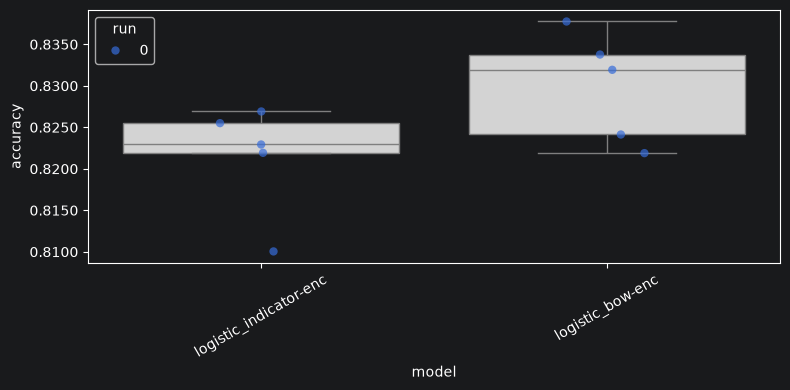

In [34]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

**All system comparisons**

We compare the two logistic regression systems to see whether counting token frequencies (BagOfWords) gives a meaningful advantage over simply recording token presence (TokenIndicator).

P(logistic_indicator-enc wins)=0.0012  P(Tie)=0.7007  P(logistic_bow-enc wins)=0.2981  Effect size=3.09


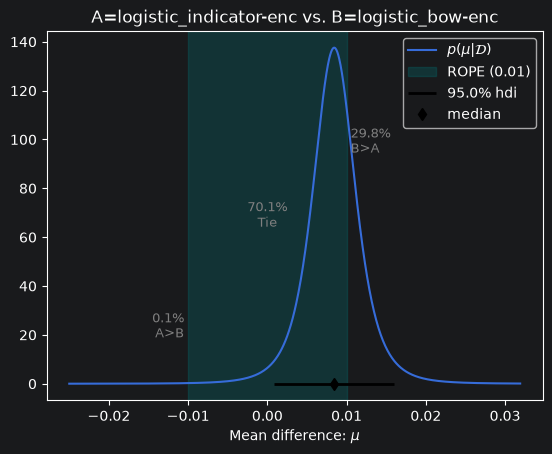

In [35]:
rope = 0.01  # 1 percentage point

pairs = [
    ('logistic_indicator-enc', 'logistic_bow-enc'),
    ('logistic_indicator-enc', 'mlp_indicator-enc'),
    ('logistic_bow-enc',       'mlp_bow-enc'),
    ('mlp_indicator-enc',      'mlp_bow-enc'),
    ('mlp_indicator-enc',      'deep_mlp_indicator-enc'),
    ('mlp_bow-enc',            'deep_mlp_bow-enc'),
]

for name_a, name_b in pairs:
    accs_a = get_all_measurements_for(my_classifiers, name_a).flatten()
    accs_b = get_all_measurements_for(my_classifiers, name_b).flatten()
    posterior = part1.analysis.BenavoliCorrelatedT(accs_a, accs_b, names=[name_a, name_b])
    p_a, p_tie, p_b = posterior.probs(rope)
    print(f"P({name_a} wins)={p_a:.4f}  P(Tie)={p_tie:.4f}  P({name_b} wins)={p_b:.4f}  Effect size={posterior.effect_size:.2f}")
    _ = posterior.plot(rope)

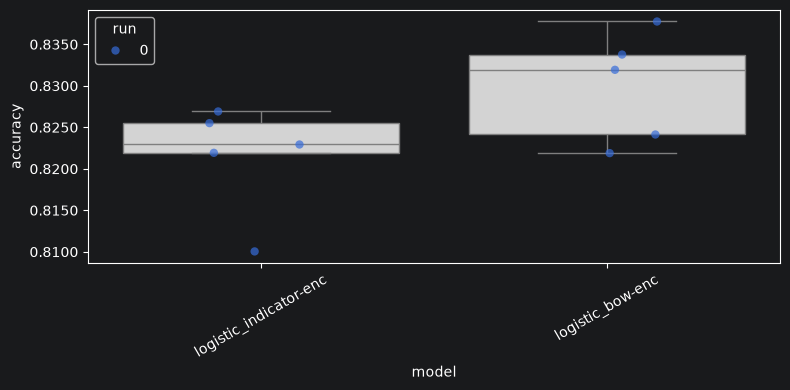

In [36]:
df = part1.analysis.make_data_frame(my_classifiers)
part1.analysis.plot_box_and_points(df)

**Interpretation:**

- 70% probability of a tie — the two systems are practically equivalent within the 1pp ROPE most of the time
- 30% chance BoW wins, only 0.1% chance TokenIndicator wins
- Effect size of 3.09 — large, meaning BoW does tend to score higher, but the difference is small enough in absolute terms to often fall within the ROPE

BagOfWords is likely better than TokenIndicator for logistic regression on IMDb, but the difference is small enough that we can't confidently say it matters in practice. This makes intuitive sense — for sentiment, knowing a word appears vs. how often it appears (e.g. "great great great") adds some signal but not dramatically so.